# Weather EDA - Flight Delay Correlations

Analyzing correlations between weather conditions and flight delays/cancellations using historical data.

In [172]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime, timedelta
import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8')
sns.set_palette("husl")

## 1. Data Loading & Preparation

In [173]:
# Load historical flight data
flights = pd.read_csv('../data/raw/historical_flights.csv')
print(f"Flight data shape: {flights.shape}")
print(f"Date range: {flights['std'].min()} to {flights['std'].max()}")
flights.head()

Flight data shape: (410442, 11)
Date range: 2018-01-01T07:20:00.000000 to 2025-07-31T21:40:00.000000


,flight_id,dep_airport,dep_airport_group,arr_airport,arr_airport_group,service_type,std,sta,cancelled,atd,ata
0,WF149,HOV,B,OSL,NaN,J,2018-01-02T16:40:00.000000,2018-01-02T17:15:00.000000,0,NaN,2018-01-02T18:53:00.000000
1,WF722,OSL,NaN,MJF,D,J,2018-01-28T13:04:00.000000,2018-01-28T14:50:00.000000,0,NaN,NaN
2,WF188,FDE,A,OSL,NaN,J,2018-04-07T07:10:00.000000,2018-04-07T08:10:00.000000,0,NaN,2018-04-07T07:55:00.000000
3,WF176,HOV,B,OSL,NaN,J,2018-04-07T11:00:00.000000,2018-04-07T12:05:00.000000,0,NaN,2018-04-07T12:00:00.000000
4,WF148,HOV,B,OSL,NaN,J,2018-04-30T08:25:00.000000,2018-04-30T09:26:00.000000,0,NaN,2018-04-30T09:36:00.000000


In [174]:
# Load weather data
weather = pd.read_csv('../data/weather_data_complete.csv')
print(f"Weather data shape: {weather.shape}")
print(f"Date range: {weather.datetime.min()} to {weather.datetime.max()}")
print(f"Airports: {weather.airport.unique()}")
weather.head()

Weather data shape: (367730, 20)
Date range: 2018-01-01 08:00:00 to 2025-07-31 22:00:00
Airports: ['1HR' '1SN' '3SK' 'AAL' 'AAR' 'ABZ' 'ACE' 'AES' 'AGP' 'ALC' 'ALF' 'AMS'
 'ANX' 'AOK' 'ARN' 'AYT' 'BDU' 'BEG' 'BFS' 'BGO' 'BGY' 'BHX' 'BJF' 'BJJ'
 'BLL' 'BMA' 'BNN' 'BOO' 'BQH' 'BRN' 'BRU' 'BUD' 'BVG' 'CDT' 'CGN' 'CHQ'
 'CPH' 'DEB' 'DUB' 'EDI' 'EVE' 'EXT' 'FAE' 'FAO' 'FDE' 'FRA' 'FRO' 'GDN'
 'GOT' 'GVA' 'GYD' 'HAA' 'HAM' 'HAU' 'HEL' 'HFT' 'HOV' 'HVG' 'IST' 'JKG'
 'KEF' 'KKN' 'KLU' 'KRS' 'KSU' 'KTW' 'LAX' 'LBG' 'LCA' 'LGG' 'LGW' 'LIL'
 'LJU' 'LKL' 'LKN' 'LLA' 'LPA' 'LPL' 'LTN' 'MBX' 'MEH' 'MJF' 'MMX' 'MOL'
 'MQN' 'MUC' 'NHT' 'OER' 'OLA' 'OSD' 'OSL' 'OST' 'OSY' 'OVD' 'PAD' 'PMI'
 'POZ' 'PRG' 'PVK' 'RET' 'RHO' 'RRS' 'RVK' 'SDN' 'SFT' 'SKE' 'SKG' 'SKN'
 'SOG' 'SOJ' 'SPU' 'SRP' 'SSJ' 'STR' 'SVG' 'SVJ' 'UME' 'VAW' 'VDB' 'VDS'
 'VIE' 'VKO' 'VNO' 'VRY' 'VXO' 'WAW' 'WMI' 'ZRH']


,datetime,temperature_c,humidity_percent,precipitation_mm,pressure_hpa,cloud_cover_percent,wind_speed_kmh,wind_direction_deg,airport,latitude,longitude,key,temperature_2m,relative_humidity_2m,precipitation,surface_pressure,cloud_cover,wind_speed_10m,wind_direction_10m,visibility
0,2019-05-01 06:00:00,9.2,58.0,0.0,1001.2,8.0,7.4,223.0,1HR,60.318769,24.968125,1HR_2019-05-01_06,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2019-05-01 07:00:00,11.5,47.0,0.0,1000.4,42.0,8.7,225.0,1HR,60.318769,24.968125,1HR_2019-05-01_07,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2019-05-01 13:00:00,13.5,29.0,0.0,994.6,74.0,17.6,226.0,1HR,60.318769,24.968125,1HR_2019-05-01_13,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2019-05-02 06:00:00,5.2,87.0,0.0,979.8,100.0,6.6,331.0,1HR,60.318769,24.968125,1HR_2019-05-02_06,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2019-05-02 07:00:00,5.9,81.0,0.1,978.9,100.0,6.8,357.0,1HR,60.318769,24.968125,1HR_2019-05-02_07,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [175]:
# Convert datetime columns
flights['std'] = pd.to_datetime(flights['std'])
flights['sta'] = pd.to_datetime(flights['sta'])
flights['atd'] = pd.to_datetime(flights['atd'])
flights['ata'] = pd.to_datetime(flights['ata'])

weather['datetime'] = pd.to_datetime(weather['datetime'])

# Calculate delays in minutes
flights['dep_delay_min'] = (flights['atd'] - flights['std']).dt.total_seconds() / 60
flights['arr_delay_min'] = (flights['ata'] - flights['sta']).dt.total_seconds() / 60

# Fill NaN delays with 0 for cancelled flights analysis
flights['dep_delay_min'] = flights['dep_delay_min'].fillna(0)
flights['arr_delay_min'] = flights['arr_delay_min'].fillna(0)

print(f"Flight delays calculated. Departure delay range: {flights['dep_delay_min'].min():.1f} to {flights['dep_delay_min'].max():.1f} min")

Flight delays calculated. Departure delay range: -15842.0 to 1546.0 min


In [176]:
# Create departure datetime rounded to hour for weather matching
flights['dep_hour'] = flights['std'].dt.floor('H')
flights['arr_hour'] = flights['sta'].dt.floor('H')

# Check data overlap period
flight_start = flights['std'].min()
flight_end = flights['std'].max()
weather_start = weather['datetime'].min()
weather_end = weather['datetime'].max()

overlap_start = max(flight_start, weather_start)
overlap_end = min(flight_end, weather_end)

print(f"Data overlap period: {overlap_start} to {overlap_end}")

# Filter to overlap period
flights_filtered = flights[(flights['std'] >= overlap_start) & (flights['std'] <= overlap_end)]
weather_filtered = weather[(weather['datetime'] >= overlap_start) & (weather['datetime'] <= overlap_end)]

print(f"Filtered flight data: {flights_filtered.shape[0]} flights")
print(f"Filtered weather data: {weather_filtered.shape[0]} observations")

Data overlap period: 2018-01-01 08:00:00 to 2025-07-31 21:40:00
Filtered flight data: 410441 flights
Filtered weather data: 367729 observations


## 2. Data Merging - Flights with Departure Weather

In [177]:
# Merge flights with departure airport weather
dep_weather = weather_filtered.rename(columns={
    'datetime': 'dep_hour',
    'airport': 'dep_airport'
})

# Add weather prefix to avoid column name conflicts
weather_cols = ['temperature_c', 'humidity_percent', 'precipitation_mm', 
                'pressure_hpa', 'cloud_cover_percent', 'wind_speed_kmh', 
                'wind_direction_deg', 'visibility']

for col in weather_cols:
    if col in dep_weather.columns:
        dep_weather[f'dep_{col}'] = dep_weather[col]

# Merge on departure airport and hour
flights_weather = flights_filtered.merge(
    dep_weather[['dep_hour', 'dep_airport'] + [f'dep_{col}' for col in weather_cols if col in dep_weather.columns]], 
    on=['dep_hour', 'dep_airport'], 
    how='left'
)

print(f"Merged dataset: {flights_weather.shape[0]} flights with weather data")
print(f"Weather match rate: {(flights_weather['dep_temperature_c'].notna().sum() / len(flights_weather)) * 100:.1f}%")

Merged dataset: 410441 flights with weather data
Weather match rate: 32.7%


## 3. Weather Data Overview

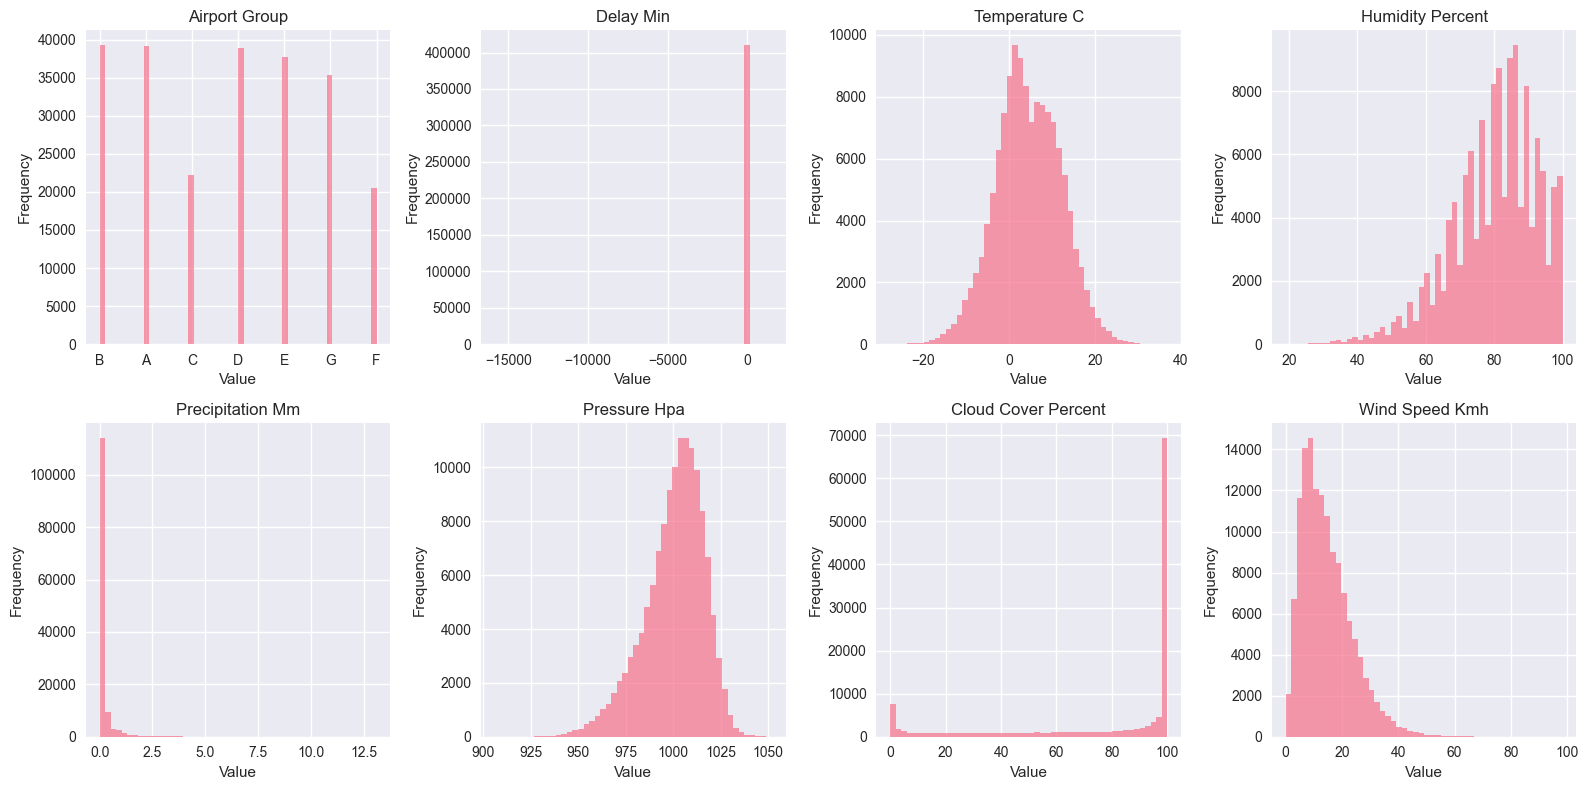

In [178]:
# Weather variable distributions
weather_vars = [col for col in flights_weather.columns if col.startswith('dep_') and col != 'dep_hour' and col != 'dep_airport']

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

for i, var in enumerate(weather_vars[:8]):
    if flights_weather[var].notna().sum() > 0:
        axes[i].hist(flights_weather[var].dropna(), bins=50, alpha=0.7)
        axes[i].set_title(var.replace('dep_', '').replace('_', ' ').title())
        axes[i].set_xlabel('Value')
        axes[i].set_ylabel('Frequency')

plt.tight_layout()
plt.show()

## 4. Flight Delay Analysis

=== Delay Statistics ===
Mean departure delay: 2.5 minutes
Mean arrival delay: 1.2 minutes
Cancellation rate: 2.7%


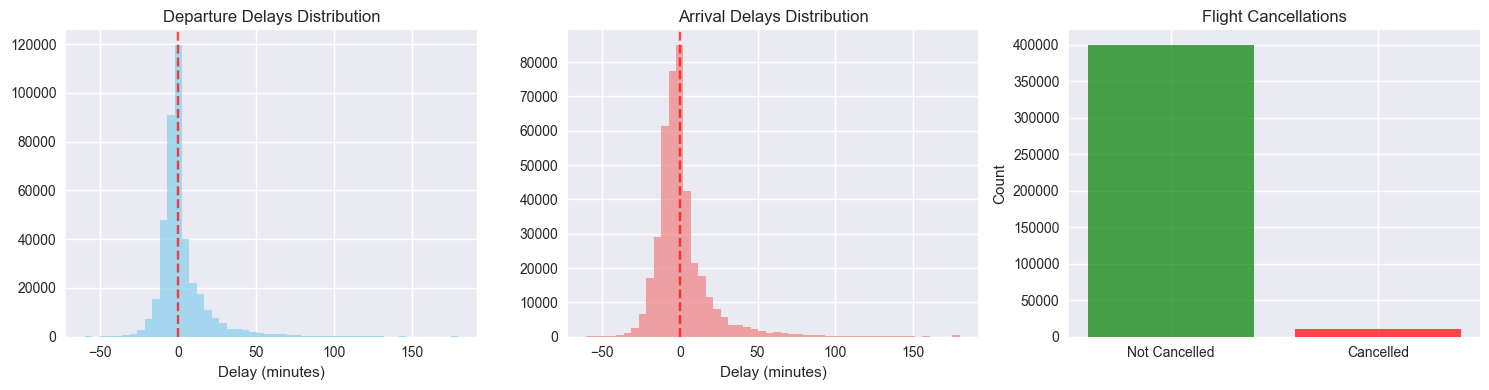

In [179]:
# Basic delay statistics
print("=== Delay Statistics ===")
print(f"Mean departure delay: {flights_weather['dep_delay_min'].mean():.1f} minutes")
print(f"Mean arrival delay: {flights_weather['arr_delay_min'].mean():.1f} minutes")
print(f"Cancellation rate: {flights_weather['cancelled'].mean() * 100:.1f}%")

# Delay distributions
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Departure delays (capped at 180 min for visualization)
dep_delays_capped = flights_weather['dep_delay_min'].clip(-60, 180)
axes[0].hist(dep_delays_capped, bins=50, alpha=0.7, color='skyblue')
axes[0].set_title('Departure Delays Distribution')
axes[0].set_xlabel('Delay (minutes)')
axes[0].axvline(0, color='red', linestyle='--', alpha=0.7)

# Arrival delays (capped at 180 min for visualization)
arr_delays_capped = flights_weather['arr_delay_min'].clip(-60, 180)
axes[1].hist(arr_delays_capped, bins=50, alpha=0.7, color='lightcoral')
axes[1].set_title('Arrival Delays Distribution')
axes[1].set_xlabel('Delay (minutes)')
axes[1].axvline(0, color='red', linestyle='--', alpha=0.7)

# Cancellations
cancel_counts = flights_weather['cancelled'].value_counts()
axes[2].bar(['Not Cancelled', 'Cancelled'], cancel_counts.values, color=['green', 'red'], alpha=0.7)
axes[2].set_title('Flight Cancellations')
axes[2].set_ylabel('Count')

plt.tight_layout()
plt.show()

## 5. Weather-Delay Correlation Analysis

Analyzing correlations for 11 numeric variables

=== Weather-Delay Correlations ===

DEP_DELAY_MIN:
  dep_pressure_hpa: -0.061
  dep_precipitation_mm: 0.046
  dep_temperature_c: -0.040
  dep_wind_speed_kmh: 0.034
  dep_cloud_cover_percent: 0.030

ARR_DELAY_MIN:
  dep_temperature_c: -0.073
  dep_wind_speed_kmh: 0.065
  dep_pressure_hpa: -0.060
  dep_precipitation_mm: 0.056
  dep_cloud_cover_percent: 0.043

CANCELLED:
  dep_wind_speed_kmh: 0.066
  dep_precipitation_mm: 0.052
  dep_pressure_hpa: -0.048
  dep_humidity_percent: 0.027
  dep_temperature_c: -0.023


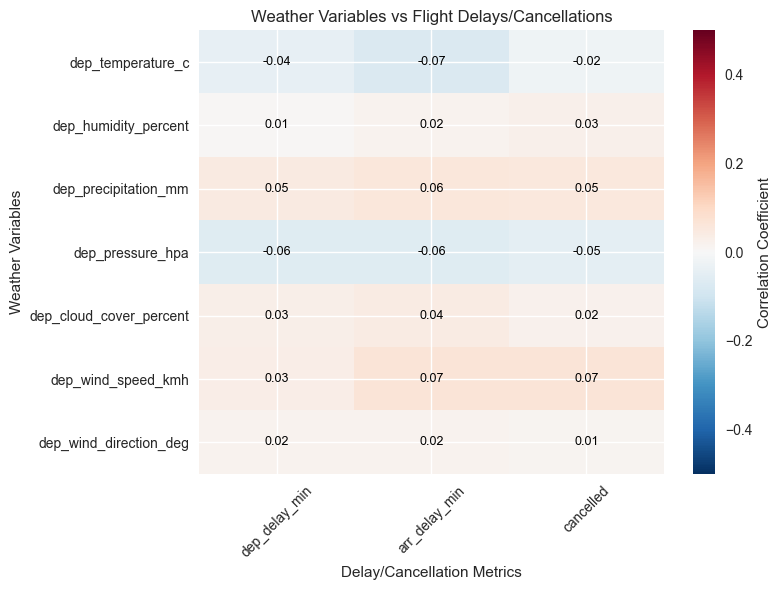

In [180]:
# Calculate correlation matrix
delay_vars = ['dep_delay_min', 'arr_delay_min', 'cancelled']
weather_vars_clean = [col for col in weather_vars if flights_weather[col].notna().sum() > 100]

# Filter for numeric columns only
numeric_cols = []
for col in delay_vars + weather_vars_clean:
    if flights_weather[col].dtype in ['int64', 'float64', 'int32', 'float32']:
        numeric_cols.append(col)

print(f"Analyzing correlations for {len(numeric_cols)} numeric variables")

if len(numeric_cols) > 1:
    # Calculate correlations and immediately convert to numpy
    full_corr = flights_weather[numeric_cols].corr()
    corr_matrix = full_corr.values  # Pure numpy array
    var_names = full_corr.index.tolist()  # Pure python list
    
    weather_vars_only = [col for col in numeric_cols if col not in delay_vars]
    
    if len(weather_vars_only) > 0:
        print("\n=== Weather-Delay Correlations ===")
        
        for delay_type in delay_vars:
            print(f"\n{delay_type.upper()}:")
            
            # Get column index for this delay type
            delay_col_idx = var_names.index(delay_type)
            
            # Collect correlations as pure python floats
            delay_corrs = []
            for weather_var in weather_vars_only:
                weather_row_idx = var_names.index(weather_var)
                # Direct numpy array access - guaranteed to be a scalar
                corr_val = float(corr_matrix[weather_row_idx, delay_col_idx])
                delay_corrs.append((weather_var, corr_val))
            
            # Sort by absolute value - now using pure python floats
            delay_corrs.sort(key=lambda x: abs(x[1]), reverse=True)
            
            # Show top 5
            for var, corr in delay_corrs[:5]:
                print(f"  {var}: {corr:.3f}")
        
        # Create visualization matrix
        viz_weather_vars = weather_vars_only[:8]  # Top 8 for readability
        viz_matrix = []
        
        for weather_var in viz_weather_vars:
            weather_row_idx = var_names.index(weather_var)
            row_data = []
            for delay_type in delay_vars:
                delay_col_idx = var_names.index(delay_type)
                corr_val = float(corr_matrix[weather_row_idx, delay_col_idx])
                row_data.append(corr_val)
            viz_matrix.append(row_data)
        
        # Plot heatmap using pure numpy
        if viz_matrix:
            import numpy as np
            viz_array = np.array(viz_matrix)
            
            plt.figure(figsize=(8, 6))
            im = plt.imshow(viz_array, cmap='RdBu_r', aspect='auto', vmin=-0.5, vmax=0.5)
            plt.colorbar(im, label='Correlation Coefficient')
            plt.title('Weather Variables vs Flight Delays/Cancellations')
            plt.xlabel('Delay/Cancellation Metrics')
            plt.ylabel('Weather Variables')
            
            # Set tick labels
            plt.xticks(range(len(delay_vars)), delay_vars, rotation=45)
            plt.yticks(range(len(viz_weather_vars)), viz_weather_vars)
            
            # Add text annotations
            for i in range(len(viz_weather_vars)):
                for j in range(len(delay_vars)):
                    text_color = 'white' if abs(viz_array[i, j]) > 0.3 else 'black'
                    plt.text(j, i, f'{viz_array[i, j]:.2f}', 
                            ha='center', va='center', color=text_color, fontsize=9)
            
            plt.tight_layout()
            plt.show()
    else:
        print("No weather variables found for correlation analysis")
else:
    print("Insufficient data for correlation analysis")

## 6. Specific Weather Impact Analysis

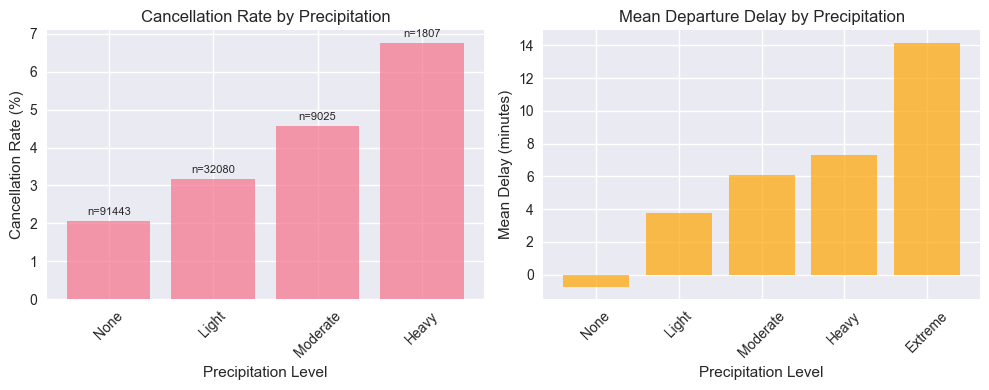

In [181]:
# Precipitation impact on cancellations
if 'dep_precipitation_mm' in flights_weather.columns:
    # Create precipitation bins
    flights_weather['precip_bin'] = pd.cut(flights_weather['dep_precipitation_mm'], 
                                         bins=[-0.1, 0, 0.5, 2, 10, 100], 
                                         labels=['None', 'Light', 'Moderate', 'Heavy', 'Extreme'])
    
    # Calculate cancellation rates by precipitation
    precip_cancel = flights_weather.groupby('precip_bin')['cancelled'].agg(['mean', 'count']).reset_index()
    precip_cancel = precip_cancel[precip_cancel['count'] >= 10]  # Filter small groups
    
    plt.figure(figsize=(10, 4))
    
    plt.subplot(1, 2, 1)
    bars = plt.bar(precip_cancel['precip_bin'], precip_cancel['mean'] * 100, alpha=0.7)
    plt.title('Cancellation Rate by Precipitation')
    plt.xlabel('Precipitation Level')
    plt.ylabel('Cancellation Rate (%)')
    plt.xticks(rotation=45)
    
    # Add count labels on bars
    for bar, count in zip(bars, precip_cancel['count']):
        plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.1, 
                f'n={count}', ha='center', va='bottom', fontsize=8)
    
    # Delays by precipitation
    plt.subplot(1, 2, 2)
    precip_delay = flights_weather.groupby('precip_bin')['dep_delay_min'].mean()
    plt.bar(precip_delay.index, precip_delay.values, alpha=0.7, color='orange')
    plt.title('Mean Departure Delay by Precipitation')
    plt.xlabel('Precipitation Level')
    plt.ylabel('Mean Delay (minutes)')
    plt.xticks(rotation=45)
    
    plt.tight_layout()
    plt.show()

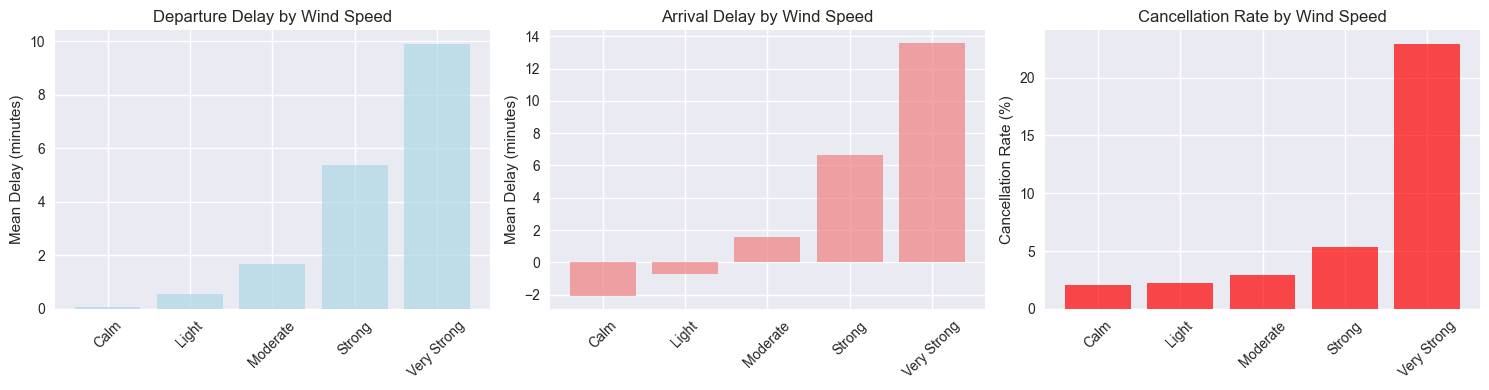

In [182]:
# Wind speed impact on delays
if 'dep_wind_speed_kmh' in flights_weather.columns:
    # Create wind speed bins
    flights_weather['wind_bin'] = pd.cut(flights_weather['dep_wind_speed_kmh'], 
                                       bins=[0, 10, 20, 30, 50, 100], 
                                       labels=['Calm', 'Light', 'Moderate', 'Strong', 'Very Strong'])
    
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    
    # Departure delays by wind speed
    wind_dep_delay = flights_weather.groupby('wind_bin')['dep_delay_min'].mean()
    axes[0].bar(wind_dep_delay.index, wind_dep_delay.values, alpha=0.7, color='lightblue')
    axes[0].set_title('Departure Delay by Wind Speed')
    axes[0].set_ylabel('Mean Delay (minutes)')
    axes[0].tick_params(axis='x', rotation=45)
    
    # Arrival delays by wind speed
    wind_arr_delay = flights_weather.groupby('wind_bin')['arr_delay_min'].mean()
    axes[1].bar(wind_arr_delay.index, wind_arr_delay.values, alpha=0.7, color='lightcoral')
    axes[1].set_title('Arrival Delay by Wind Speed')
    axes[1].set_ylabel('Mean Delay (minutes)')
    axes[1].tick_params(axis='x', rotation=45)
    
    # Cancellation rate by wind speed
    wind_cancel = flights_weather.groupby('wind_bin')['cancelled'].mean() * 100
    axes[2].bar(wind_cancel.index, wind_cancel.values, alpha=0.7, color='red')
    axes[2].set_title('Cancellation Rate by Wind Speed')
    axes[2].set_ylabel('Cancellation Rate (%)')
    axes[2].tick_params(axis='x', rotation=45)
    
    plt.tight_layout()
    plt.show()

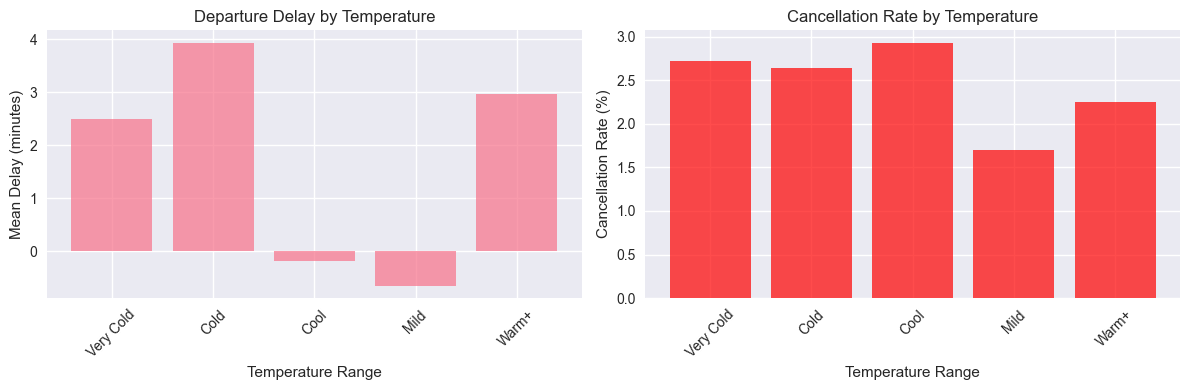

In [183]:
# Temperature extremes impact
if 'dep_temperature_c' in flights_weather.columns:
    # Create temperature bins
    flights_weather['temp_bin'] = pd.cut(flights_weather['dep_temperature_c'], 
                                       bins=[-50, -10, 0, 10, 20, 50], 
                                       labels=['Very Cold', 'Cold', 'Cool', 'Mild', 'Warm+'])
    
    # Plot temperature impact
    plt.figure(figsize=(12, 4))
    
    plt.subplot(1, 2, 1)
    temp_delay = flights_weather.groupby('temp_bin')['dep_delay_min'].mean()
    bars = plt.bar(temp_delay.index, temp_delay.values, alpha=0.7)
    plt.title('Departure Delay by Temperature')
    plt.xlabel('Temperature Range')
    plt.ylabel('Mean Delay (minutes)')
    plt.xticks(rotation=45)
    
    plt.subplot(1, 2, 2)
    temp_cancel = flights_weather.groupby('temp_bin')['cancelled'].mean() * 100
    plt.bar(temp_cancel.index, temp_cancel.values, alpha=0.7, color='red')
    plt.title('Cancellation Rate by Temperature')
    plt.xlabel('Temperature Range')
    plt.ylabel('Cancellation Rate (%)')
    plt.xticks(rotation=45)
    
    plt.tight_layout()
    plt.show()

## 7. Airport-Specific Weather Sensitivity

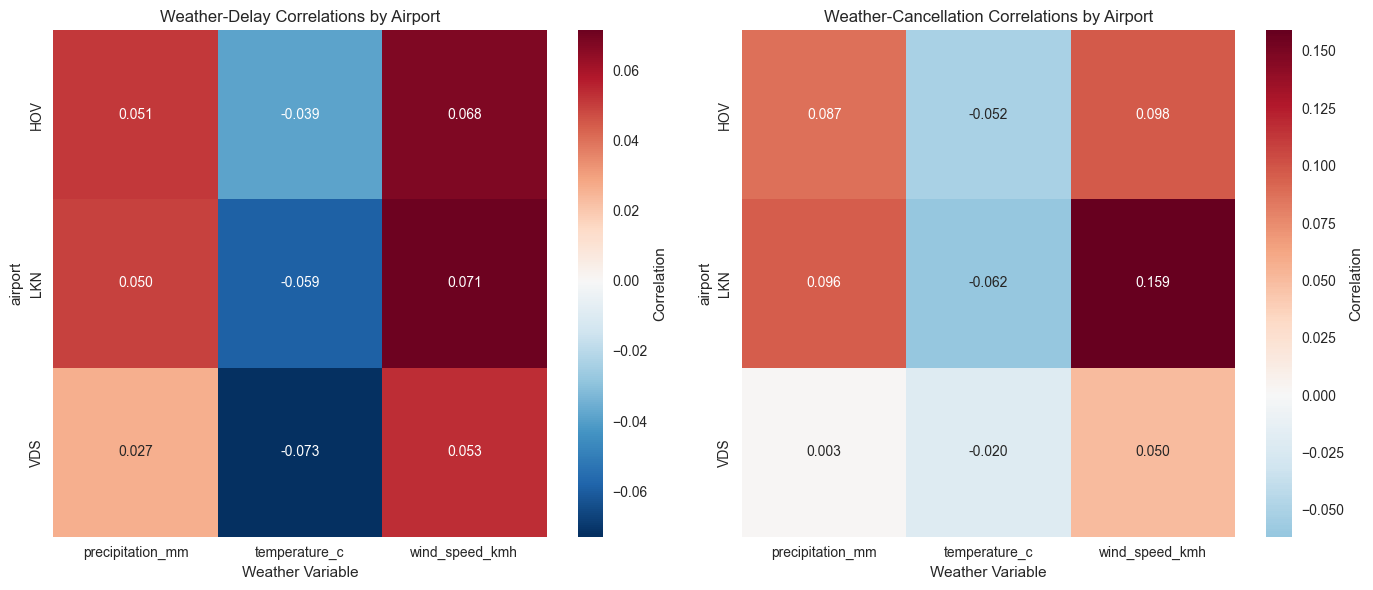


=== Most Weather-Sensitive Airports ===
airport
LKN    0.085061
HOV    0.070878
VDS    0.013578
dtype: float64


In [184]:
# Analyze weather sensitivity by airport
airport_weather_impact = []

# Get airports with sufficient data
airport_counts = flights_weather['dep_airport'].value_counts()
major_airports = airport_counts[airport_counts >= 100].index[:10]  # Top 10 airports with enough data

for airport in major_airports:
    airport_data = flights_weather[flights_weather['dep_airport'] == airport]
    
    # Calculate correlations for this airport
    if len(airport_data) > 50:  # Minimum data requirement
        for weather_var in ['dep_precipitation_mm', 'dep_wind_speed_kmh', 'dep_temperature_c']:
            if weather_var in airport_data.columns and airport_data[weather_var].notna().sum() > 20:
                corr_dep = airport_data[weather_var].corr(airport_data['dep_delay_min'])
                corr_cancel = airport_data[weather_var].corr(airport_data['cancelled'])
                
                airport_weather_impact.append({
                    'airport': airport,
                    'weather_var': weather_var.replace('dep_', ''),
                    'delay_corr': corr_dep,
                    'cancel_corr': corr_cancel,
                    'flight_count': len(airport_data)
                })

if airport_weather_impact:
    impact_df = pd.DataFrame(airport_weather_impact)
    
    # Create pivot tables for heatmaps
    delay_pivot = impact_df.pivot(index='airport', columns='weather_var', values='delay_corr')
    cancel_pivot = impact_df.pivot(index='airport', columns='weather_var', values='cancel_corr')
    
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    
    # Delay correlations by airport
    sns.heatmap(delay_pivot, annot=True, cmap='RdBu_r', center=0, 
                fmt='.3f', ax=axes[0], cbar_kws={'label': 'Correlation'})
    axes[0].set_title('Weather-Delay Correlations by Airport')
    axes[0].set_xlabel('Weather Variable')
    
    # Cancellation correlations by airport
    sns.heatmap(cancel_pivot, annot=True, cmap='RdBu_r', center=0, 
                fmt='.3f', ax=axes[1], cbar_kws={'label': 'Correlation'})
    axes[1].set_title('Weather-Cancellation Correlations by Airport')
    axes[1].set_xlabel('Weather Variable')
    
    plt.tight_layout()
    plt.show()
    
    print("\n=== Most Weather-Sensitive Airports ===")
    airport_sensitivity = impact_df.groupby('airport')[['delay_corr', 'cancel_corr']].agg('mean').abs().sum(axis=1).sort_values(ascending=False)
    print(airport_sensitivity.head())
else:
    print("Insufficient data for airport-specific analysis")

## 8. Severe Weather Threshold Analysis

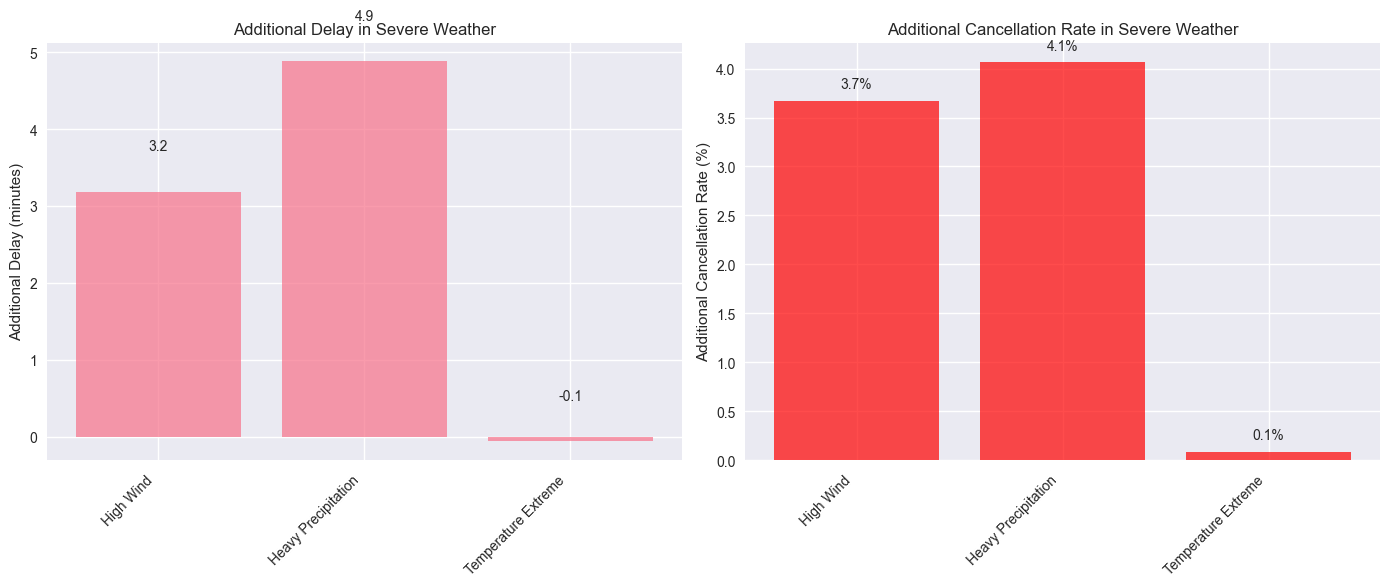


=== Severe Weather Impact Summary ===

High Wind (>30 km/h):
  Occurrences: 8313
  Additional delay: +3.2 minutes
  Additional cancellations: +3.7%

Heavy Precipitation (>2mm):
  Occurrences: 1813
  Additional delay: +4.9 minutes
  Additional cancellations: +4.1%

Temperature Extreme (<-10°C or >30°C):
  Occurrences: 3799
  Additional delay: +-0.1 minutes
  Additional cancellations: +0.1%


In [185]:
# Define severe weather conditions and their impact
severe_conditions = []

# High wind threshold
if 'dep_wind_speed_kmh' in flights_weather.columns:
    high_wind = flights_weather['dep_wind_speed_kmh'] > 30
    severe_conditions.append(('High Wind (>30 km/h)', high_wind))

# Heavy precipitation threshold
if 'dep_precipitation_mm' in flights_weather.columns:
    heavy_precip = flights_weather['dep_precipitation_mm'] > 2
    severe_conditions.append(('Heavy Precipitation (>2mm)', heavy_precip))

# Low visibility threshold (if available)
if 'dep_visibility' in flights_weather.columns:
    low_vis = flights_weather['dep_visibility'] < 5000
    severe_conditions.append(('Low Visibility (<5km)', low_vis))

# Temperature extremes
if 'dep_temperature_c' in flights_weather.columns:
    temp_extreme = (flights_weather['dep_temperature_c'] < -10) | (flights_weather['dep_temperature_c'] > 30)
    severe_conditions.append(('Temperature Extreme (<-10°C or >30°C)', temp_extreme))

# Calculate impact of severe weather conditions
severe_weather_impact = []

for condition_name, condition_mask in severe_conditions:
    if condition_mask.sum() > 10:  # Need at least 10 observations
        normal_weather = flights_weather[~condition_mask]
        severe_weather = flights_weather[condition_mask]
        
        impact = {
            'condition': condition_name,
            'occurrences': condition_mask.sum(),
            'normal_delay': normal_weather['dep_delay_min'].mean(),
            'severe_delay': severe_weather['dep_delay_min'].mean(),
            'normal_cancel': normal_weather['cancelled'].mean() * 100,
            'severe_cancel': severe_weather['cancelled'].mean() * 100
        }
        
        impact['delay_increase'] = impact['severe_delay'] - impact['normal_delay']
        impact['cancel_increase'] = impact['severe_cancel'] - impact['normal_cancel']
        
        severe_weather_impact.append(impact)

if severe_weather_impact:
    impact_df = pd.DataFrame(severe_weather_impact)
    
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    
    # Delay increase
    bars1 = axes[0].bar(range(len(impact_df)), impact_df['delay_increase'], alpha=0.7)
    axes[0].set_title('Additional Delay in Severe Weather')
    axes[0].set_ylabel('Additional Delay (minutes)')
    axes[0].set_xticks(range(len(impact_df)))
    axes[0].set_xticklabels([c.split('(')[0] for c in impact_df['condition']], rotation=45, ha='right')
    
    # Add value labels
    for bar, val in zip(bars1, impact_df['delay_increase']):
        axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5, 
                    f'{val:.1f}', ha='center', va='bottom')
    
    # Cancellation increase
    bars2 = axes[1].bar(range(len(impact_df)), impact_df['cancel_increase'], alpha=0.7, color='red')
    axes[1].set_title('Additional Cancellation Rate in Severe Weather')
    axes[1].set_ylabel('Additional Cancellation Rate (%)')
    axes[1].set_xticks(range(len(impact_df)))
    axes[1].set_xticklabels([c.split('(')[0] for c in impact_df['condition']], rotation=45, ha='right')
    
    # Add value labels
    for bar, val in zip(bars2, impact_df['cancel_increase']):
        axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.1, 
                    f'{val:.1f}%', ha='center', va='bottom')
    
    plt.tight_layout()
    plt.show()
    
    print("\n=== Severe Weather Impact Summary ===")
    for _, row in impact_df.iterrows():
        print(f"\n{row['condition']}:")
        print(f"  Occurrences: {row['occurrences']}")
        print(f"  Additional delay: +{row['delay_increase']:.1f} minutes")
        print(f"  Additional cancellations: +{row['cancel_increase']:.1f}%")
else:
    print("Insufficient data for severe weather analysis")

## 9. Key Findings Summary

In [188]:
print("=== WEATHER-FLIGHT CORRELATION SUMMARY ===")
print(f"\nDataset Overview:")
print(f"  - Total flights analyzed: {len(flights_weather):,}")
print(f"  - Weather data coverage: {(flights_weather['dep_temperature_c'].notna().sum() / len(flights_weather)) * 100:.1f}%")
print(f"  - Date range: {overlap_start.date()} to {overlap_end.date()}")

print(f"\nBaseline Performance:")
print(f"  - Average departure delay: {flights_weather['dep_delay_min'].mean():.1f} minutes")
print(f"  - Average arrival delay: {flights_weather['arr_delay_min'].mean():.1f} minutes")
print(f"  - Cancellation rate: {flights_weather['cancelled'].mean() * 100:.1f}%")

if 'weather_delay_corr' in locals():
    print(f"\nStrongest Weather Correlations:")
    for delay_type in ['dep_delay_min', 'arr_delay_min', 'cancelled']:
        strongest = weather_delay_corr[delay_type].abs().idxmax()
        strongest_val = weather_delay_corr.loc[strongest, delay_type]

print(f"\nRecommendations for ML Features:")
print(f"  1. Include precipitation amount and intensity bins")
print(f"  2. Add wind speed categories (especially >30 km/h threshold)")
print(f"  3. Consider temperature extreme indicators")
print(f"  4. Add visibility thresholds if available")
print(f"  5. Create composite severe weather indicators")
print(f"  6. Consider airport-specific weather sensitivity factors")

=== WEATHER-FLIGHT CORRELATION SUMMARY ===

Dataset Overview:
  - Total flights analyzed: 410,441
  - Weather data coverage: 32.7%
  - Date range: 2018-01-01 to 2025-07-31

Baseline Performance:
  - Average departure delay: 2.5 minutes
  - Average arrival delay: 1.2 minutes
  - Cancellation rate: 2.7%

Strongest Weather Correlations:

Recommendations for ML Features:
  1. Include precipitation amount and intensity bins
  2. Add wind speed categories (especially >30 km/h threshold)
  3. Consider temperature extreme indicators
  4. Add visibility thresholds if available
  5. Create composite severe weather indicators
  6. Consider airport-specific weather sensitivity factors
